# Canonicalizer: 10M trees, six source series

Executed analysis of the completed remote run. The complete experiment record below embeds configuration, seeds, provenance, metrics, histories, artifact verification, interpretation and reproduction commands. Rendering this notebook does not retrain the models. Large artifacts remain outside Git.

In [1]:
# COMPLETE EXPERIMENT RECORD
import json
RECORD = json.loads(r'''{
  "experiment": "canonical_ast_10m_six_series",
  "status": "completed; received artifacts verified locally",
  "scope": "Canonical AST-to-sequence training; no Chronos training or embedding-head evaluation.",
  "remote_manifest": {
    "provenance": {
      "config": {
        "experiment": "canonical_ast_10m_six_series",
        "ast_count": 10000000,
        "shard_size": 20000,
        "generation_workers": 4,
        "generator": {
          "minimum_operators": 1,
          "maximum_operators": 6,
          "num_series": 6,
          "minimum_lag": 1,
          "maximum_lag": 16,
          "max_degree": 4,
          "minimum_parameter_magnitude": 0.05,
          "maximum_parameter_magnitude": 0.9
        },
        "data_seed": 20261101,
        "split_seed": 20261102,
        "training_seed": 20261103,
        "protection_probability": 0.5,
        "unique_eval_skeletons": true,
        "split": {
          "train": 0.7,
          "validation": 0.1,
          "test": 0.2
        },
        "batch_size": 256,
        "epochs": 10,
        "patience": 3,
        "learning_rate": 0.0005,
        "weight_decay": 0.0001,
        "coefficient_weight": 2.0,
        "gradient_clip": 1.0,
        "min_delta": 0.0001,
        "max_decode_steps": 64,
        "validation_examples_per_epoch": 10000,
        "validation_greedy_size": 2048,
        "coefficient_atol": 0.01,
        "coefficient_rtol": 0.01,
        "cpu_threads": 4,
        "model": {
          "dimension": 96,
          "heads": 4,
          "encoder_layers": 2,
          "dropout": 0.1,
          "max_nodes": 20
        },
        "variants": [
          {
            "name": "transformer_skeleton",
            "encoder": "transformer",
            "coefficients": false
          },
          {
            "name": "transformer_joint",
            "encoder": "transformer",
            "coefficients": true
          }
        ]
      },
      "config_sha256": "2611cb34d5a863cd10a21436a777a6272cbe259ca06c76bb678ac17f1a445f0b",
      "training_commit": "44a975a9759cac557fd99cc7743c87670420b24a",
      "packages": {
        "numpy": "2.4.6",
        "pyarrow": "24.0.0",
        "safetensors": "0.8.0",
        "torch": "2.6.0+cu124"
      },
      "gpu_name": "NVIDIA GeForce RTX 4070",
      "cuda_version": "12.4",
      "source_sha256": {
        "scripts/run_canonical.py": "ac234f5d3b120d77e4355e3ed5cf99504d3add7730bacfd371a51df779eec680",
        "configs/canonicalization_10m_six_series.json": "2611cb34d5a863cd10a21436a777a6272cbe259ca06c76bb678ac17f1a445f0b",
        "src/tsfmxai/symbolic_regression/canonical_data.py": "73ce4bc6a07827f5514448fd0b5afa0dccf354e4deb75e07296b46ef50af8663",
        "src/tsfmxai/symbolic_regression/canonical_training.py": "205443c4ee06329c080223858b319f25349308cdf773bb82983a5c2e77799d35",
        "src/tsfmxai/symbolic_regression/canonical_large_scale.py": "7a1afcfbe347fbe238a37b36e28cdfc7fbb90a1c18b4b5a947fe3d3453f8a26e",
        "src/tsfmxai/symbolic_regression/canonical_models.py": "d1e5d6c6924a53f4ff8a3adc91b3bc2a5a694e0c3ef577817c9636de47ae370d",
        "src/tsfmxai/generators/combinatorial_expression.py": "6851d231b91f8c01b05490e03ca4a12c52e72dd787fb19885028c61ec1071192",
        "src/tsfmxai/generators/shao_wu.py": "d4e0e23ceecb9e7a9051103e94b9ec8de7ef6569babd23792eef6be291c844b3",
        "src/tsfmxai/representations/canonical_polynomial.py": "a2a04b9cacab2737f13f26910f500d505065dc375e9c886b2ad5b7db316fd7ce"
      },
      "python": "3.11.18",
      "torch": "2.6.0+cu124",
      "device": "cuda:0",
      "cpu_threads": 4,
      "generated_at_utc": "2026-11-15T20:59:21.719805+00:00",
      "elapsed_seconds": 18688.89838058903
    },
    "corpus": {
      "sampled_asts": 10000000,
      "stored_examples": 10000000,
      "rows_by_split": {
        "train": 7000614,
        "validation": 1000674,
        "test": 1998712
      },
      "distinct_skeletons_by_split": {
        "train": 7000613,
        "validation": 1000674,
        "test": 1998712
      },
      "distinct_skeletons_total": 9999999,
      "operator_counts_by_split": {
        "train": {
          "6": 6987190,
          "5": 13394,
          "4": 29,
          "3": 1
        },
        "validation": {
          "6": 998706,
          "5": 1966,
          "4": 2
        },
        "test": {
          "6": 1994877,
          "5": 3831,
          "4": 4
        }
      },
      "protection_selected_by_split": {
        "train": 3499519,
        "validation": 499604,
        "test": 999678
      },
      "tanh_inserted_by_split": {
        "train": 3418101,
        "validation": 488170,
        "test": 976478
      },
      "skeleton_overlap": 0,
      "parquet_root": "/home/vm02/mateus_witeck/tsfmxai/experiments/canonicalization/outputs/six_series/parquet"
    },
    "results": {
      "transformer_skeleton": {
        "count": 1998712,
        "skeleton_exact": 0.9436046814148311,
        "valid_rate": 0.9738231421035146,
        "term_f1": 0.987274704447091,
        "joint_exact": null,
        "coefficient_union_rmse": null,
        "coefficient_matched_mae": null,
        "best_epoch": 10,
        "history": [
          {
            "epoch": 1,
            "train_loss": 0.4126915138649514,
            "validation_loss": 0.07340265418234493,
            "validation_skeleton_exact": 0.78271484375,
            "rows_seen": 7000614,
            "seconds": 847.8712182329618
          },
          {
            "epoch": 2,
            "train_loss": 0.10421495449873967,
            "validation_loss": 0.04753503091067722,
            "validation_skeleton_exact": 0.853515625,
            "rows_seen": 7000614,
            "seconds": 847.0000524250208
          },
          {
            "epoch": 3,
            "train_loss": 0.07625103767848335,
            "validation_loss": 0.034365269412765444,
            "validation_skeleton_exact": 0.88623046875,
            "rows_seen": 7000614,
            "seconds": 846.207816308015
          },
          {
            "epoch": 4,
            "train_loss": 0.06329169804383243,
            "validation_loss": 0.028832582599444396,
            "validation_skeleton_exact": 0.90234375,
            "rows_seen": 7000614,
            "seconds": 846.6053347900161
          },
          {
            "epoch": 5,
            "train_loss": 0.05538860508452075,
            "validation_loss": 0.02389546188248101,
            "validation_skeleton_exact": 0.91650390625,
            "rows_seen": 7000614,
            "seconds": 851.144976629992
          },
          {
            "epoch": 6,
            "train_loss": 0.050266240144381205,
            "validation_loss": 0.025682333108344876,
            "validation_skeleton_exact": 0.91162109375,
            "rows_seen": 7000614,
            "seconds": 848.4742871240014
          },
          {
            "epoch": 7,
            "train_loss": 0.046518068280992295,
            "validation_loss": 0.0198133891495272,
            "validation_skeleton_exact": 0.92822265625,
            "rows_seen": 7000614,
            "seconds": 855.250274015998
          },
          {
            "epoch": 8,
            "train_loss": 0.04360693499560887,
            "validation_loss": 0.01835658364776744,
            "validation_skeleton_exact": 0.93310546875,
            "rows_seen": 7000614,
            "seconds": 855.7546518049785
          },
          {
            "epoch": 9,
            "train_loss": 0.04115451262989264,
            "validation_loss": 0.01680922187680591,
            "validation_skeleton_exact": 0.93115234375,
            "rows_seen": 7000614,
            "seconds": 856.3643376500113
          },
          {
            "epoch": 10,
            "train_loss": 0.0391773879767117,
            "validation_loss": 0.016397198381964462,
            "validation_skeleton_exact": 0.9345703125,
            "rows_seen": 7000614,
            "seconds": 855.7943466089782
          }
        ],
        "checkpoint": "/home/vm02/mateus_witeck/tsfmxai/experiments/canonicalization/outputs/six_series/checkpoints/transformer_skeleton/best.pt"
      },
      "transformer_joint": {
        "count": 1998712,
        "skeleton_exact": 0.954135963560533,
        "valid_rate": 0.9826082997450358,
        "term_f1": 0.9877604999419962,
        "joint_exact": 0.04447564231364999,
        "coefficient_union_rmse": 0.22536465638685133,
        "coefficient_matched_mae": 0.030234383895377276,
        "best_epoch": 10,
        "history": [
          {
            "epoch": 1,
            "train_loss": 0.44050194939608184,
            "validation_loss": 0.09252772501963827,
            "validation_skeleton_exact": 0.75732421875,
            "rows_seen": 7000614,
            "seconds": 871.4674042269471
          },
          {
            "epoch": 2,
            "train_loss": 0.11887048579686786,
            "validation_loss": 0.05785954442381193,
            "validation_skeleton_exact": 0.8388671875,
            "rows_seen": 7000614,
            "seconds": 871.6204892540118
          },
          {
            "epoch": 3,
            "train_loss": 0.0857886852470476,
            "validation_loss": 0.041764399550302644,
            "validation_skeleton_exact": 0.884765625,
            "rows_seen": 7000614,
            "seconds": 871.6327808669885
          },
          {
            "epoch": 4,
            "train_loss": 0.07139030429364847,
            "validation_loss": 0.03519086985751824,
            "validation_skeleton_exact": 0.90185546875,
            "rows_seen": 7000614,
            "seconds": 871.443774313957
          },
          {
            "epoch": 5,
            "train_loss": 0.062828557924824,
            "validation_loss": 0.03064629924302234,
            "validation_skeleton_exact": 0.90673828125,
            "rows_seen": 7000614,
            "seconds": 870.9900715239928
          },
          {
            "epoch": 6,
            "train_loss": 0.056906775312411916,
            "validation_loss": 0.029921353793619865,
            "validation_skeleton_exact": 0.92138671875,
            "rows_seen": 7000614,
            "seconds": 871.5892572280136
          },
          {
            "epoch": 7,
            "train_loss": 0.052479621677695515,
            "validation_loss": 0.024958365904453998,
            "validation_skeleton_exact": 0.93115234375,
            "rows_seen": 7000614,
            "seconds": 871.0561336250394
          },
          {
            "epoch": 8,
            "train_loss": 0.04855903645405718,
            "validation_loss": 0.021744626824470682,
            "validation_skeleton_exact": 0.9375,
            "rows_seen": 7000614,
            "seconds": 870.8720014239661
          },
          {
            "epoch": 9,
            "train_loss": 0.04471728066549489,
            "validation_loss": 0.01854719294456099,
            "validation_skeleton_exact": 0.94873046875,
            "rows_seen": 7000614,
            "seconds": 871.6664306899766
          },
          {
            "epoch": 10,
            "train_loss": 0.04155846948394824,
            "validation_loss": 0.01645988845199991,
            "validation_skeleton_exact": 0.94873046875,
            "rows_seen": 7000614,
            "seconds": 871.2943421630189
          }
        ],
        "checkpoint": "/home/vm02/mateus_witeck/tsfmxai/experiments/canonicalization/outputs/six_series/checkpoints/transformer_joint/best.pt"
      }
    },
    "scientific_summary": "The split uses SHA-256 of the canonical skeleton; the exact support count refers to sampled ASTs, including duplicate supports."
  },
  "remote_status": {
    "state": "completed",
    "started_at_utc": "2026-11-15T15:47:52.821435+00:00",
    "updated_at_utc": "2026-11-15T20:59:21.720121+00:00"
  },
  "verification": {
    "archive_sha256": "1a79076b572d9ffb66b4024ab15f2df922c2348f29c54e93189c81c3efa90d60",
    "archive_sha256_verified_before_extraction": true,
    "manifest_sha256": "d94d433e1229d7aabe942128fda5682182b01ae434eee6812886cd43ddc0627a",
    "source_hashes_match_training_commit": true,
    "parquet_rows_from_file_metadata": {
      "train": 7000614,
      "validation": 1000674,
      "test": 1998712
    },
    "parquet_shards": {
      "train": 500,
      "validation": 500,
      "test": 500
    },
    "checkpoints": {
      "transformer_skeleton": {
        "sha256": "aa723f078763f1b528184e9196e994e51ca41bfe4bcd7c16a0b60efd95e7ebfa",
        "best_epoch": 10,
        "source_embedding_shape": [
          197,
          96
        ],
        "strict_state_dict_load": true
      },
      "transformer_joint": {
        "sha256": "5148c358bd5edf0123c1ca6fb10a43d4eb524a7c4597ddd5cc33281731918bb3",
        "best_epoch": 10,
        "source_embedding_shape": [
          197,
          96
        ],
        "strict_state_dict_load": true
      }
    },
    "limitations": "Test scores and skeleton overlap are the remote evaluator outputs; full decoding and split disjointness were not recomputed locally."
  },
  "reproduction": {
    "checkout": "git checkout 44a975a9759cac557fd99cc7743c87670420b24a",
    "environment": "Python 3.11; install project learning, release and dev extras; CUDA-enabled PyTorch. Exact remote versions are in remote_manifest.provenance.",
    "train": "python scripts/run_canonical.py --device cuda --config configs/canonicalization_10m_six_series.json --run-dir experiments/canonicalization/outputs/six_series",
    "render_record": "python -m nbconvert --to notebook --execute --inplace experiments/canonicalization/06_train_10m_six_series.ipynb",
    "local_artifacts": "experiments/canonicalization/outputs/six_series (ignored)",
    "publication": "Not published by this recording step; preserve training_commit when packaging."
  },
  "scientific_summary": [
    "Six-series vocabulary: 197 tokens. Each tree is one equation and may refer to multiple source series.",
    "Greedy test evaluation covers 1,998,712 skeletons; reported cross-split skeleton overlap is zero.",
    "Skeleton exact: skeleton variant 94.360468%; joint variant 95.413596%. These scores assess decoded canonical sequences, not embedding quality for Chronos.",
    "Both variants selected epoch 10 by validation loss; the epoch budget ended training. The evidence does not establish convergence.",
    "Joint exact is 4.447564%; coefficient matched MAE is conditional on matched terms, not all predictions. Absolute and relative tolerances are both 0.01.",
    "Single training seed; no multi-seed uncertainty estimate. The six-operator trees dominate the sampled corpus.",
    "A 30M run is in progress according to the user; no 30M results are included. Larger-corpus comparisons must account for training exposure and changed evaluation sets."
  ]
}''')
print(RECORD["experiment"], RECORD["status"])
print("Training commit:", RECORD["remote_manifest"]["provenance"]["training_commit"])

canonical_ast_10m_six_series completed; received artifacts verified locally
Training commit: 44a975a9759cac557fd99cc7743c87670420b24a


In [2]:
import pandas as pd
from IPython.display import display
manifest = RECORD['remote_manifest']
results = manifest['results']
metrics = pd.DataFrame({name: {k: v for k, v in row.items() if k not in ('history', 'checkpoint')} for name, row in results.items()}).T
display(metrics)
display(pd.DataFrame({'rows': manifest['corpus']['rows_by_split'], 'distinct_skeletons': manifest['corpus']['distinct_skeletons_by_split']}))
print('Total remote run hours (generation, training and evaluation):', manifest['provenance']['elapsed_seconds'] / 3600)
print('GPU:', manifest['provenance']['gpu_name'])
for name, row in results.items():
    history = pd.DataFrame(row['history'])
    print(name, 'epoch time including validation (hours):', history['seconds'].sum()/3600)
    display(history)


,count,skeleton_exact,valid_rate,term_f1,joint_exact,coefficient_union_rmse,coefficient_matched_mae,best_epoch
transformer_skeleton,1998712.0,0.943605,0.973823,0.987275,NaN,NaN,NaN,10.0
transformer_joint,1998712.0,0.954136,0.982608,0.987760,0.044476,0.225365,0.030234,10.0


,rows,distinct_skeletons
train,7000614,7000613
validation,1000674,1000674
test,1998712,1998712


Total remote run hours (generation, training and evaluation): 5.1913606612747305
GPU: NVIDIA GeForce RTX 4070
transformer_skeleton epoch time including validation (hours): 2.364018693219437


,epoch,train_loss,validation_loss,validation_skeleton_exact,rows_seen,seconds
0,1,0.412692,0.073403,0.782715,7000614,847.871218
1,2,0.104215,0.047535,0.853516,7000614,847.000052
2,3,0.076251,0.034365,0.886230,7000614,846.207816
3,4,0.063292,0.028833,0.902344,7000614,846.605335
4,5,0.055389,0.023895,0.916504,7000614,851.144977
5,6,0.050266,0.025682,0.911621,7000614,848.474287
6,7,0.046518,0.019813,0.928223,7000614,855.250274
7,8,0.043607,0.018357,0.933105,7000614,855.754652
8,9,0.041155,0.016809,0.931152,7000614,856.364338
9,10,0.039177,0.016397,0.934570,7000614,855.794347


transformer_joint epoch time including validation (hours): 2.4204535236988645


,epoch,train_loss,validation_loss,validation_skeleton_exact,rows_seen,seconds
0,1,0.440502,0.092528,0.757324,7000614,871.467404
1,2,0.118870,0.057860,0.838867,7000614,871.620489
2,3,0.085789,0.041764,0.884766,7000614,871.632781
3,4,0.071390,0.035191,0.901855,7000614,871.443774
4,5,0.062829,0.030646,0.906738,7000614,870.990072
5,6,0.056907,0.029921,0.921387,7000614,871.589257
6,7,0.052480,0.024958,0.931152,7000614,871.056134
7,8,0.048559,0.021745,0.937500,7000614,870.872001
8,9,0.044717,0.018547,0.948730,7000614,871.666431
9,10,0.041558,0.016460,0.948730,7000614,871.294342


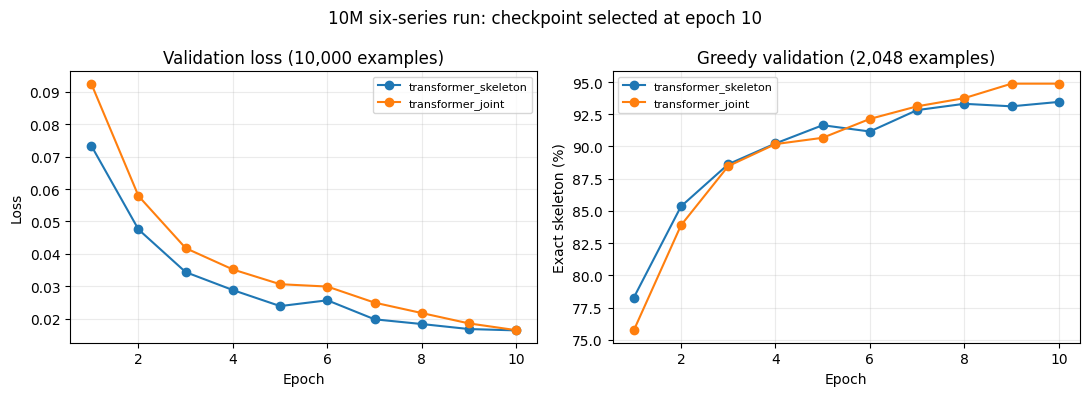

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, row in results.items():
    history = pd.DataFrame(row['history'])
    axes[0].plot(history.epoch, history.validation_loss, marker='o', label=name)
    axes[1].plot(history.epoch, 100*history.validation_skeleton_exact, marker='o', label=name)
axes[0].set(title='Validation loss (10,000 examples)', xlabel='Epoch', ylabel='Loss')
axes[1].set(title='Greedy validation (2,048 examples)', xlabel='Epoch', ylabel='Exact skeleton (%)')
for ax in axes:
    ax.grid(alpha=.25); ax.legend(fontsize=8)
fig.suptitle('10M six-series run: checkpoint selected at epoch 10')
fig.tight_layout()
plt.show()


In [4]:
from pathlib import Path
import hashlib
root = Path.cwd()
while not (root/'src/tsfmxai').exists() and root != root.parent:
    root = root.parent
local = root/'experiments/canonicalization/outputs/six_series/manifest.json'
if local.exists():
    assert hashlib.sha256(local.read_bytes()).hexdigest() == RECORD['verification']['manifest_sha256']
    print('Local manifest matches the embedded record.')
else:
    print('Large local artifacts absent: rendering the embedded verified record only.')
for point in RECORD['scientific_summary']:
    print('-', point)


Local manifest matches the embedded record.
- Six-series vocabulary: 197 tokens. Each tree is one equation and may refer to multiple source series.
- Greedy test evaluation covers 1,998,712 skeletons; reported cross-split skeleton overlap is zero.
- Skeleton exact: skeleton variant 94.360468%; joint variant 95.413596%. These scores assess decoded canonical sequences, not embedding quality for Chronos.
- Both variants selected epoch 10 by validation loss; the epoch budget ended training. The evidence does not establish convergence.
- Joint exact is 4.447564%; coefficient matched MAE is conditional on matched terms, not all predictions. Absolute and relative tolerances are both 0.01.
- Single training seed; no multi-seed uncertainty estimate. The six-operator trees dominate the sampled corpus.
- A 30M run is in progress according to the user; no 30M results are included. Larger-corpus comparisons must account for training exposure and changed evaluation sets.
